# S10: Deep-learning data pipeline

This notebook presents the outputs of `build_cache.py`, which turns the 482 development cases into network-ready arrays (`urbanwind.dl.cache`) and checks the patch sampler that S11 trains on (`urbanwind.dl.datasets`). It only reads the saved outputs; the stage card is `README.md`.

**What the cache holds.** Every case on one 1 m grid, turned so the wind blows within 0° to 45° of +columns, with five input channels (height, building mask, periodic wall distance, cos and sin of the wind angle), the target U/u* and the mask of valid cells. The frozen test groups never enter it.

In [1]:
import json
import pathlib

import pandas as pd
from IPython.display import Image, display

OUT = pathlib.Path.cwd()
while not (OUT / "pyproject.toml").exists():
    OUT = OUT.parent
OUT = OUT / "pipeline" / "S10_dl_data_pipeline" / "outputs"
FIG = OUT / "figures"
pd.set_option("display.precision", 4)


def as_table(values: dict) -> pd.DataFrame:
    # floats in short form, so a tiny difference does not print as 0
    return pd.Series({k: f"{v:.3g}" if isinstance(v, float) else v for k, v in values.items()}, name="value").to_frame()


summary = pd.read_csv(OUT / "cache_summary.csv")
checks = json.loads((OUT / "checks.json").read_text())

## 1. The cases

The 0.5 m cases (all idealized ones and four realistic ones) are merged into 2×2 blocks. A block takes the tallest of its four heights and the mean of its four wind values, and it is valid only when all four sub-cells are valid.

In [2]:
sizes = summary.groupby("subset").agg(cases=("case", "size"), at_0p5m=("dx_native", lambda d: int((d == 0.5).sum())),
                                     rows_min=("ny_1m", "min"), rows_max=("ny_1m", "max"),
                                     cols_min=("nx_1m", "min"), cols_max=("nx_1m", "max"))
display(sizes)
display(summary["status"].value_counts().rename("cases"))

,cases,at_0p5m,rows_min,rows_max,cols_min,cols_max
subset,,,,,,
idealized,190,190,60,192,100,384
realistic,292,4,240,1152,168,1056


status
ok      476
flag      6
Name: cases, dtype: int64

## 2. The canonical frame

Each case is turned by a multiple of 90° (`k` quarter turns) and transposed if needed. Without Coriolis forcing the turned case solves the same equations, so this changes nothing physical; it only means the network always sees the wind coming from the same side.

,k,transposed,cases,raw_directions,canonical_angles
0,0,False,396,"[0.0, 15.0, 22.5, 30.0, 45.0]","[0.0, 15.0, 22.5, 30.0, 45.0]"
1,0,True,2,"[60.0, 75.0]","[15.0, 30.0]"
2,1,False,74,[90.0],[0.0]
3,3,False,7,"[270.0, 285.0, 292.5, 300.0, 315.0]","[0.0, 15.0, 22.5, 30.0, 45.0]"
4,3,True,3,"[330.0, 337.5, 345.0]","[15.0, 22.5, 30.0]"


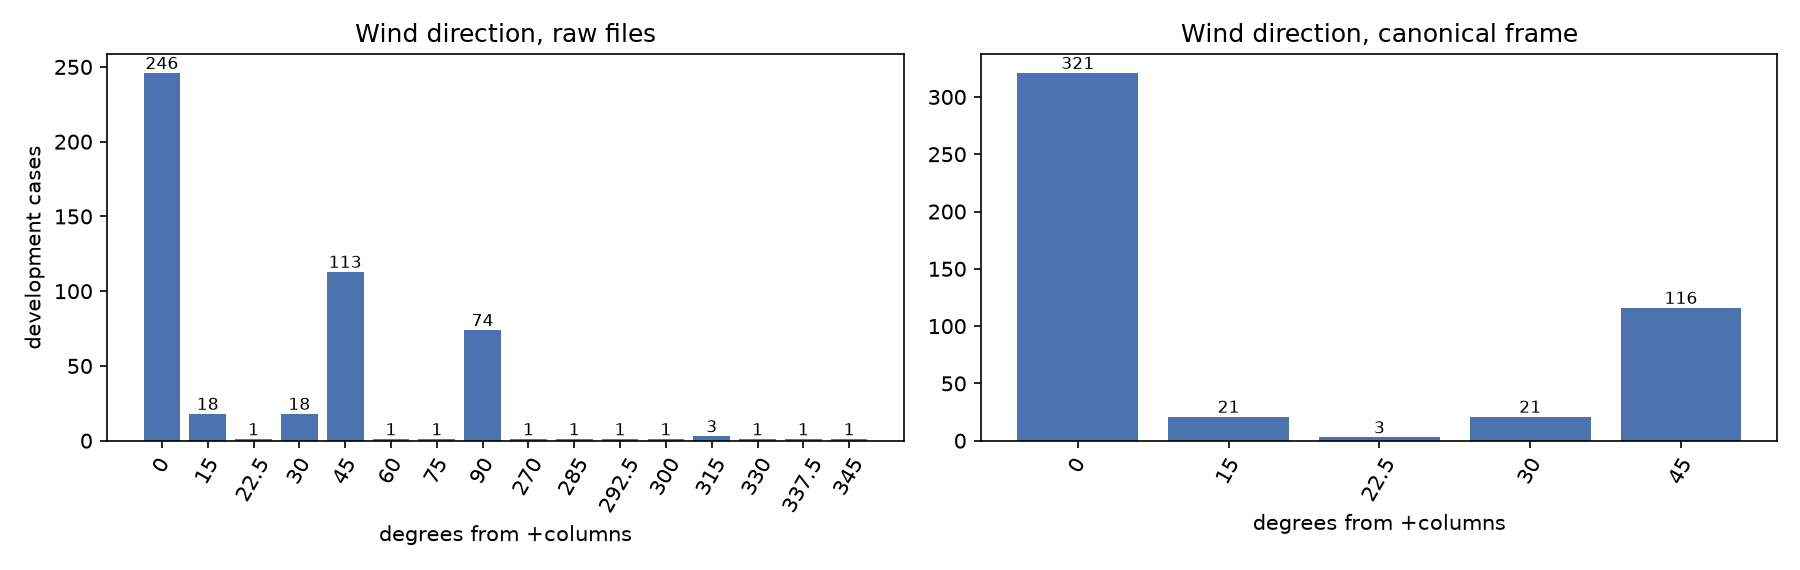

In [3]:
frame = (summary.groupby(["k", "transposed"])
         .agg(cases=("case", "size"), raw_directions=("wind_dir_deg", lambda d: sorted(set(d))),
              canonical_angles=("angle_deg", lambda d: sorted(set(d))))
         .reset_index())
display(frame)
display(Image(FIG / "wind_angles.png"))

The figure below shows one case per kind of transform: a 0.5 m idealized case at 45° (resampled, not turned), a city at 90° (one quarter turn) and a city at 60° (transposed to 30°). The wakes behind the buildings follow the red arrow in every panel, including the mirrored copy used for augmentation.

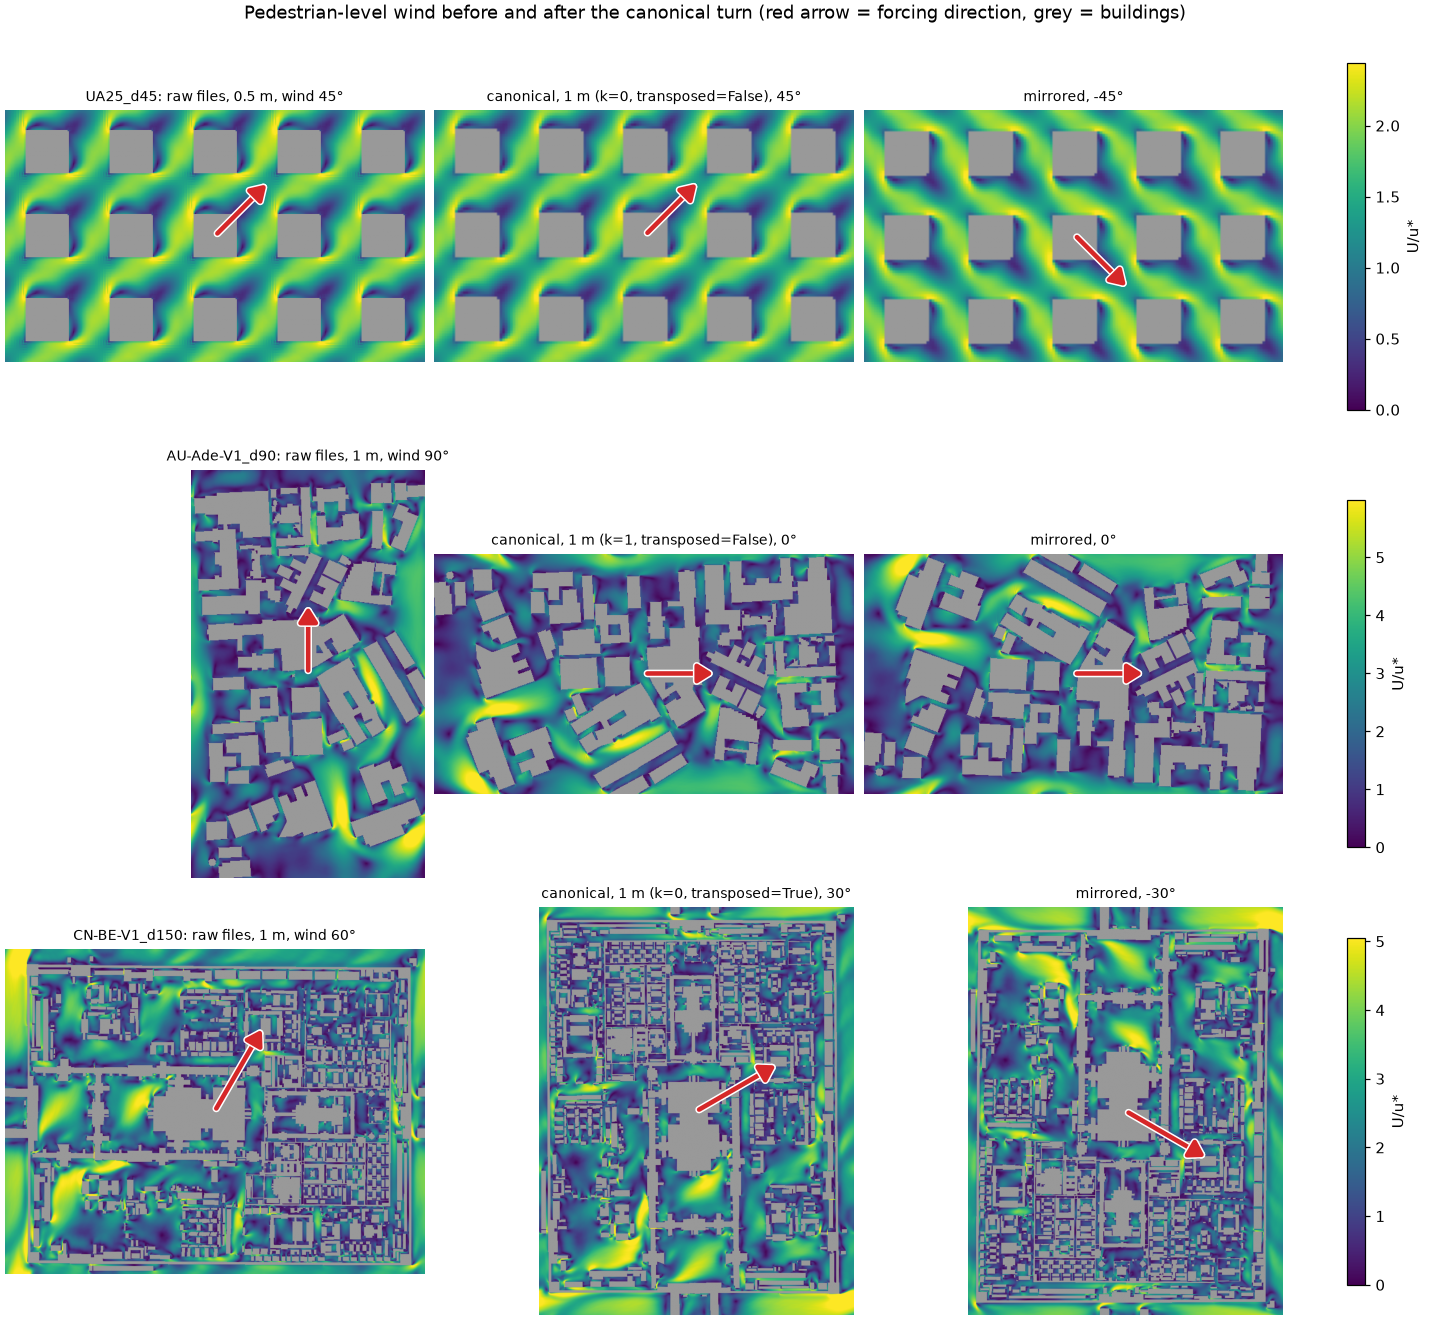

In [4]:
display(Image(FIG / "canonical_frame.png"))

## 3. Checks

Every cached case is turned back and compared with the loader. The height field must match exactly and the missing cells must be the same. The angle between the mean wind and the forcing must survive the turn, which shows that u and v were turned with the field.

In [5]:
rows = {k: v for k, v in checks.items() if k not in ("loader", "timing", "transform_counts", "n_by_subset")}
display(as_table(rows))

,value
n_cases,482
n_resampled_from_0p5m,194
cache_files_match_dev_cases,True
n_test_groups_in_cache,0
U_mean_max_rel_diff_vs_S02,4.52e-06
H_round_trip_exact_all,True
U_nan_pattern_matches_all,True
U_native_exact_all,True
U_float16_max_error,0.00391
flow_offset_preserved_max_gap_deg,0.0023


## 4. Training patches

S11 draws 256×256 patches that wrap around the domain edges, with a 16-cell border left out of the loss, since circular padding joins the opposite edges of a patch. The numbers come from drawing 1,000 batches of 16 patches exactly as training will.

,value
dataset_load_s,5
n_batches,1000
batch_size,16
patch,256
border,16
patches_per_epoch,1586
seconds_per_batch,0.0249
loss_cells_fraction_mean,0.568
loss_cells_fraction_min,0.486
patches_without_loss_cells,0


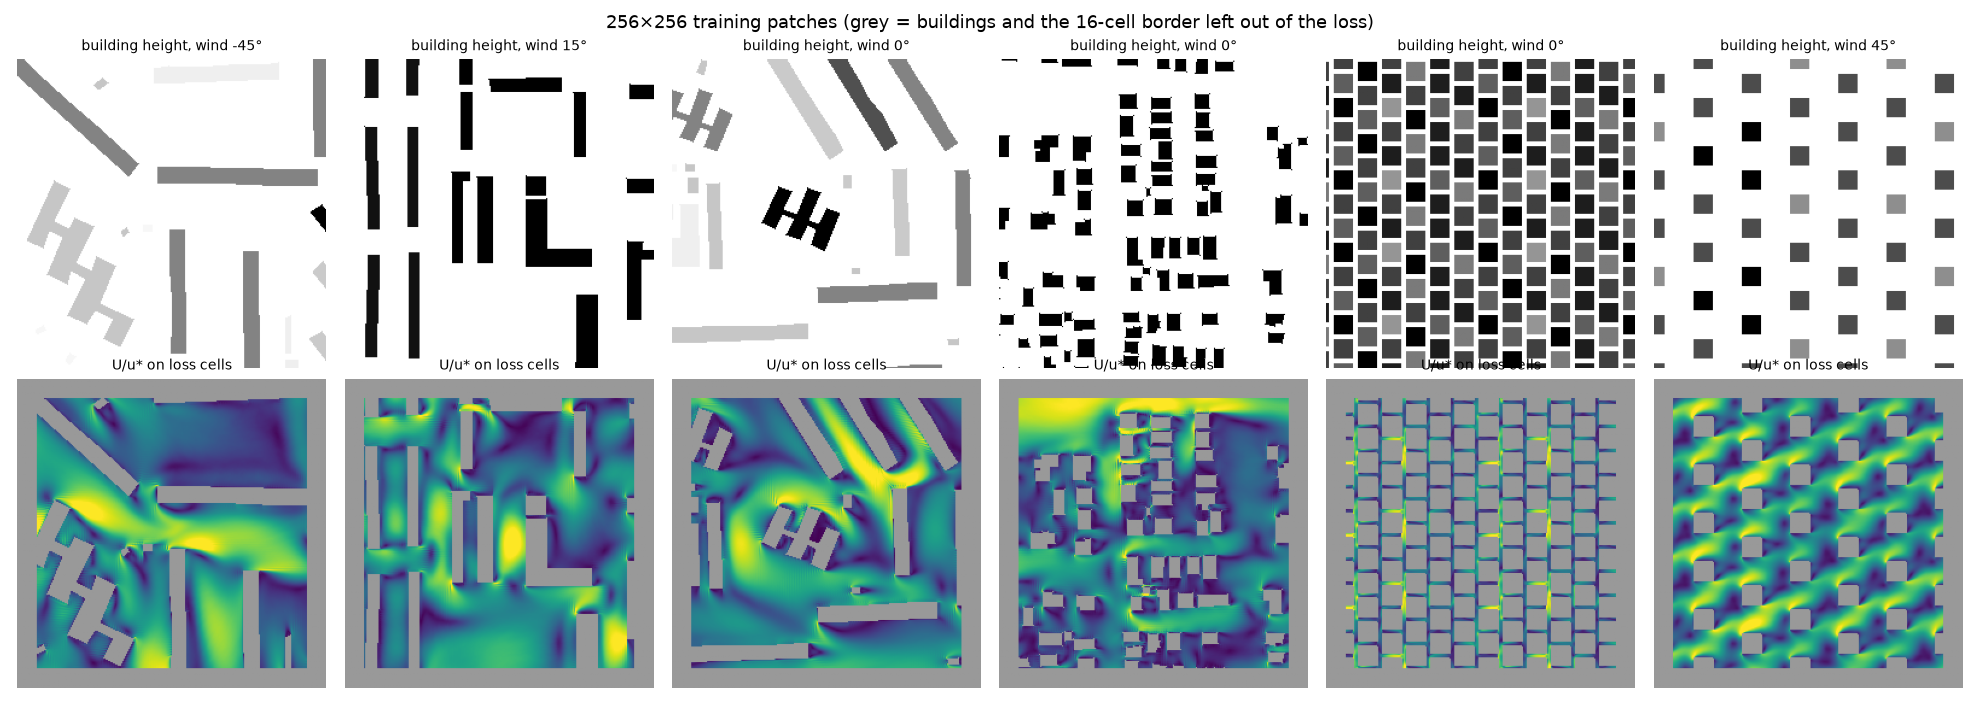

In [6]:
display(as_table(checks["loader"] | checks["timing"]))
display(Image(FIG / "sample_patches.png"))

## 5. Two things later stages should know

**Cells next to walls in 0.5 m cases.** A 1 m block that straddles a wall holds a building, so the network is never trained there, yet the evaluator still scores the block's open 0.5 m sub-cells. `predict_arrays` gives every building cell the prediction of the nearest open cell, using the input only. The table shows what share of each 0.5 m case's scored cells this concerns; for 1 m cases it is zero.

In [7]:
fine = summary[summary["dx_native"] == 0.5].assign(share_filled=lambda d: d["n_scored_filled"] / d["n_valid_native"])
display(fine.groupby("subset")["share_filled"].describe()[["count", "mean", "50%", "max"]])
print("1 m cases with any filled scored cell:", int((summary.loc[summary["dx_native"] == 1.0, "n_scored_filled"] > 0).sum()))

,count,mean,50%,max
subset,,,,
idealized,190.0,0.0192,0.0000,0.1328
realistic,4.0,0.0340,0.0361,0.0456


1 m cases with any filled scored cell: 0


**Reverse flow near the ground.** In some cases the mean wind at 1.75 m points against the forcing: the air in the streets circulates back under the flow above. The vertical profiles confirm it (see the README), so this is physics, not a sign error. It matters only to anyone who uses the u and v components.

In [8]:
reverse = summary[summary["flow_offset_native_deg"].abs() > 90]
display(reverse.groupby(["subset", "wind_dir_deg"]).size().rename("cases").to_frame())

cases
subset    wind_dir_deg       
idealized 0.0              21
realistic 0.0              12
          15.0              2
          90.0              6